In [1]:
# importing necessary dependencies
import pandas as pd # for dataset manipulation
import numpy as np # for numerical operations

In [2]:
# loan_history= pd.read_csv("../dataset/LoanDataset.csv", index_col="customer_id")
loan_history= pd.read_csv("../dataset/LoanDataset.csv")
loan_history

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
0,1.0,22,59000,RENT,123.0,PERSONAL,C,"£35,000.00",16.02,10,Y,3,DEFAULT
1,2.0,21,9600,OWN,5.0,EDUCATION,A,"£1,000.00",11.14,1,NaN,2,NO DEFAULT
2,3.0,25,9600,MORTGAGE,1.0,MEDICAL,B,"£5,500.00",12.87,5,N,3,DEFAULT
3,4.0,23,65500,RENT,4.0,MEDICAL,B,"£35,000.00",15.23,10,N,2,DEFAULT
4,5.0,24,54400,RENT,8.0,MEDICAL,B,"£35,000.00",14.27,10,Y,4,DEFAULT
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32581,32577.0,57,53000,MORTGAGE,1.0,PERSONAL,C,"£5,800.00",13.16,7,NaN,30,NO DEFAULT
32582,32578.0,54,120000,MORTGAGE,4.0,PERSONAL,A,"£17,625.00",7.49,4,NaN,19,NO DEFAULT
32583,32579.0,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,"£35,000.00",10.99,5,N,28,DEFAULT
32584,32580.0,56,150000,MORTGAGE,5.0,PERSONAL,B,"£15,000.00",11.48,6,NaN,26,NO DEFAULT


## Questions to ask about a dataset

In [3]:
# Q1. How big is the dataset?

loan_history.shape

(32586, 13)

In [4]:
# Q2. What does the dataset look like?

loan_history.sample(10)

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
26510,26507.0,30,30000,RENT,1.0,PERSONAL,B,"£14,500.00",NaN,3,N,8,DEFAULT
21547,21544.0,28,31000,RENT,3.0,PERSONAL,D,"£6,000.00",15.33,8,NaN,9,NO DEFAULT
27708,27705.0,33,158000,MORTGAGE,11.0,PERSONAL,D,"£15,000.00",16.32,3,Y,5,DEFAULT
9095,9094.0,23,61000,RENT,3.0,VENTURE,B,"£8,000.00",13.22,3,Y,2,NO DEFAULT
32425,32421.0,57,77385,RENT,4.0,VENTURE,A,"£6,625.00",7.66,7,N,29,NO DEFAULT
30701,30697.0,39,61766,MORTGAGE,4.0,EDUCATION,A,"£5,500.00",7.14,9,N,15,NO DEFAULT
3039,3038.0,24,72000,RENT,8.0,PERSONAL,B,"£3,200.00",13.92,4,NaN,3,NO DEFAULT
15549,15546.0,24,145000,MORTGAGE,0.0,HOMEIMPROVEMENT,A,"£7,000.00",10.99,4,NaN,3,NO DEFAULT
20924,20921.0,27,44200,MORTGAGE,11.0,MEDICAL,C,"£11,500.00",15.27,7,Y,10,NO DEFAULT
17734,17731.0,22,26400,RENT,1.0,PERSONAL,B,"£3,500.00",15.27,2,NaN,3,NO DEFAULT


In [5]:
# Q3. What are the datatypes of the dataset?

loan_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 32586 entries, 0 to 32585
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          32583 non-null  float64
 1   customer_age         32586 non-null  int64  
 2   customer_income      32586 non-null  str    
 3   home_ownership       32586 non-null  str    
 4   employment_duration  31691 non-null  float64
 5   loan_intent          32586 non-null  str    
 6   loan_grade           32586 non-null  str    
 7   loan_amnt            32585 non-null  str    
 8   loan_int_rate        29470 non-null  float64
 9   term_years           32586 non-null  int64  
 10  historical_default   11849 non-null  str    
 11  cred_hist_length     32586 non-null  int64  
 12  Current_loan_status  32582 non-null  str    
dtypes: float64(3), int64(3), str(7)
memory usage: 4.5 MB


In [6]:
# Q4. Does the dataset have null values?

loan_history.isnull().sum()

customer_id                3
customer_age               0
customer_income            0
home_ownership             0
employment_duration      895
loan_intent                0
loan_grade                 0
loan_amnt                  1
loan_int_rate           3116
term_years                 0
historical_default     20737
cred_hist_length           0
Current_loan_status        4
dtype: int64

In [7]:
# Q5. How does the dataset look mathematically?

loan_history.describe()

,customer_id,customer_age,employment_duration,loan_int_rate,term_years,cred_hist_length
count,32583.000000,32586.000000,31691.000000,29470.000000,32586.000000,32586.000000
mean,16289.497806,27.732769,4.790161,11.011553,4.761738,5.804026
std,9405.919628,6.360528,4.142746,3.240440,2.471107,4.055078
min,1.000000,3.000000,0.000000,5.420000,1.000000,2.000000
25%,8144.500000,23.000000,2.000000,7.900000,3.000000,3.000000
50%,16288.000000,26.000000,4.000000,10.990000,4.000000,4.000000
75%,24433.500000,30.000000,7.000000,13.470000,7.000000,8.000000
max,32581.000000,144.000000,123.000000,23.220000,10.000000,30.000000


In [8]:
# Q6. Are there any duplicate rows in the dataset?

loan_history.duplicated().sum()

np.int64(6)

In [9]:
# Q7. How do columns relate?

loan_history.corr(numeric_only=True)

,customer_id,customer_age,employment_duration,loan_int_rate,term_years,cred_hist_length
customer_id,1.000000,0.732546,0.186977,0.001857,0.143589,0.772947
customer_age,0.732546,1.000000,0.162576,0.012748,0.136092,0.857460
employment_duration,0.186977,0.162576,1.000000,-0.056532,0.075717,0.144820
loan_int_rate,0.001857,0.012748,-0.056532,1.000000,0.043807,0.016608
term_years,0.143589,0.136092,0.075717,0.043807,1.000000,0.182438
cred_hist_length,0.772947,0.857460,0.144820,0.016608,0.182438,1.000000


## Preprocessing

In [10]:
# Finding number of null values in each feature

for i in loan_history.columns:
    print(i, end= ": ")
    print(loan_history[i].isnull().sum())

customer_id: 3
customer_age: 0
customer_income: 0
home_ownership: 0
employment_duration: 895
loan_intent: 0
loan_grade: 0
loan_amnt: 1
loan_int_rate: 3116
term_years: 0
historical_default: 20737
cred_hist_length: 0
Current_loan_status: 4


In [11]:
loan_history.dropna(subset=['customer_id', 'loan_amnt', 'Current_loan_status'],inplace=True)
loan_history

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
0,1.0,22,59000,RENT,123.0,PERSONAL,C,"£35,000.00",16.02,10,Y,3,DEFAULT
1,2.0,21,9600,OWN,5.0,EDUCATION,A,"£1,000.00",11.14,1,NaN,2,NO DEFAULT
2,3.0,25,9600,MORTGAGE,1.0,MEDICAL,B,"£5,500.00",12.87,5,N,3,DEFAULT
3,4.0,23,65500,RENT,4.0,MEDICAL,B,"£35,000.00",15.23,10,N,2,DEFAULT
4,5.0,24,54400,RENT,8.0,MEDICAL,B,"£35,000.00",14.27,10,Y,4,DEFAULT
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32581,32577.0,57,53000,MORTGAGE,1.0,PERSONAL,C,"£5,800.00",13.16,7,NaN,30,NO DEFAULT
32582,32578.0,54,120000,MORTGAGE,4.0,PERSONAL,A,"£17,625.00",7.49,4,NaN,19,NO DEFAULT
32583,32579.0,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,"£35,000.00",10.99,5,N,28,DEFAULT
32584,32580.0,56,150000,MORTGAGE,5.0,PERSONAL,B,"£15,000.00",11.48,6,NaN,26,NO DEFAULT


In [12]:
# identifying duplicate rows in the dataset

loan_history.duplicated().sum()

np.int64(6)

In [13]:
loan_history = loan_history.drop_duplicates() # removing the duplicate rows from the entire dataset

In [14]:
loan_history.sample(10)

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
1044,1043.0,26,80171,RENT,3.0,HOMEIMPROVEMENT,B,"£18,000.00",13.85,9,NaN,3,NO DEFAULT
3364,3363.0,21,36000,RENT,3.0,HOMEIMPROVEMENT,A,"£11,000.00",10.37,8,N,4,DEFAULT
7473,7472.0,22,37000,RENT,6.0,PERSONAL,A,"£6,800.00",7.14,2,NaN,2,NO DEFAULT
11304,11303.0,23,73000,MORTGAGE,7.0,VENTURE,A,"£7,000.00",10.74,3,NaN,3,NO DEFAULT
5442,5441.0,21,45000,MORTGAGE,5.0,PERSONAL,A,"£4,000.00",7.14,1,NaN,3,NO DEFAULT
12673,12672.0,26,84000,MORTGAGE,10.0,DEBTCONSOLIDATION,A,"£3,000.00",9.63,6,NaN,3,NO DEFAULT
6655,6654.0,23,54000,RENT,0.0,EDUCATION,B,"£6,000.00",12.53,3,Y,4,NO DEFAULT
10874,10873.0,22,70000,MORTGAGE,4.0,VENTURE,A,"£13,750.00",10.75,7,NaN,3,NO DEFAULT
21038,21035.0,28,53000,RENT,2.0,MEDICAL,A,"£8,500.00",5.79,8,NaN,9,NO DEFAULT
31098,31094.0,38,75971,MORTGAGE,10.0,HOMEIMPROVEMENT,D,"£18,125.00",14.84,8,Y,12,NO DEFAULT


In [15]:
print(loan_history['loan_int_rate'].to_string())

0        16.02
1        11.14
2        12.87
3        15.23
4        14.27
5         7.14
6        12.42
7        11.11
8         8.90
9        14.74
10       10.37
11        8.63
12        7.90
13       18.39
14        7.90
15       10.65
16        7.90
17       20.25
18       18.25
19       10.99
20        7.49
21       16.77
22       17.58
23        7.29
24       14.54
25       12.68
26       17.74
27        9.32
28        9.99
29       12.84
30       11.12
31        6.62
32       14.17
33       13.85
34       13.49
35        7.51
36       18.39
37       14.54
38       16.89
39         NaN
40       17.99
41       12.69
42        7.88
43       19.41
44       10.38
45       15.33
46       16.45
47        7.49
48       12.69
49        6.62
50         NaN
51       18.62
52       15.23
53       10.65
54        7.90
55       15.96
56       11.48
57         NaN
58        7.29
59         NaN
60        5.99
61       11.58
62         NaN
63       15.70
64       15.99
65       14.84
66       1

> ### Using statistical method to fill the missing values

In [16]:
# interest_rate= sorted(loan_history['loan_int_rate'])
# interest_rate

In [17]:
# fig, axs = plt.subplots(1,3)

# axs[0].set_title("Loan interest Rate VS Historical Default")
# sns.barplot(y=loan_history['loan_int_rate'], x=loan_history['historical_default'], ax=axs[0])
# axs[1].set_title("Loan interest Rate VS Employment Duration")
# sns.barplot(x=loan_history['loan_int_rate'], y=loan_history['employment_duration'], ax=axs[1])
# axs[2].set_title("Employment Duration VS Historical Default")
# sns.barplot(y=loan_history['employment_duration'], x=loan_history['historical_default'], ax=axs[2])

In [18]:
# removing the pound '£' symbol

def str_normalizer(string):
    string = str(string)
    return string.replace('£','').replace(',','')

loan_history['loan_amnt']       = loan_history['loan_amnt'].apply(str_normalizer)
loan_history['customer_income'] = loan_history['customer_income'].apply(str_normalizer)

loan_history['loan_amnt']       = loan_history['loan_amnt'].astype(float)
loan_history['customer_income'] = loan_history['customer_income'].astype(float)


loan_history['loan_amnt'].info()
print('='*60)
loan_history['customer_income'].info()
print("="*60)
loan_history['term_years'].info()

<class 'pandas.Series'>
Index: 32572 entries, 0 to 32585
Series name: loan_amnt
Non-Null Count  Dtype  
--------------  -----  
32572 non-null  float64
dtypes: float64(1)
memory usage: 508.9 KB
<class 'pandas.Series'>
Index: 32572 entries, 0 to 32585
Series name: customer_income
Non-Null Count  Dtype  
--------------  -----  
32572 non-null  float64
dtypes: float64(1)
memory usage: 508.9 KB
<class 'pandas.Series'>
Index: 32572 entries, 0 to 32585
Series name: term_years
Non-Null Count  Dtype
--------------  -----
32572 non-null  int64
dtypes: int64(1)
memory usage: 508.9 KB


Text(0.5, 1.0, 'Term Year')

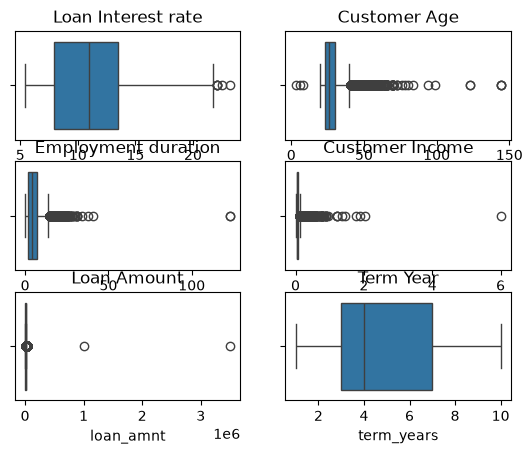

In [19]:
# identifying outliers in the feature using Quartiles(Box plot)
import seaborn as sns            # for using boxplot function
import matplotlib.pyplot as plt  # for plotting on graph

fig, axs = plt.subplots(3,2)

# Create the box plot
sns.boxplot(x=loan_history['loan_int_rate'], ax= axs[0,0])
axs[0,0].set_title("Loan Interest rate")

sns.boxplot(x=loan_history['employment_duration'], ax= axs[1,0])
axs[1,0].set_title("Employment duration")

sns.boxplot(x=loan_history['loan_amnt'], ax= axs[2,0])
axs[2,0].set_title("Loan Amount")

sns.boxplot(x=loan_history['customer_age'], ax= axs[0,1])
axs[0,1].set_title("Customer Age")

sns.boxplot(x=loan_history['customer_income'], ax= axs[1,1])
axs[1,1].set_title("Customer Income")

sns.boxplot(x=loan_history['term_years'], ax= axs[2,1])
axs[2,1].set_title("Term Year")

{'whiskers': [<matplotlib.lines.Line2D at 0x221d90f74d0>,
 'caps': [<matplotlib.lines.Line2D at 0x221d90f7770>,
 'boxes': [<matplotlib.lines.Line2D at 0x221d90f7380>],
 'medians': [<matplotlib.lines.Line2D at 0x221d90f7a10>],
 'fliers': [<matplotlib.lines.Line2D at 0x221d90f7b60>],
 'means': []}

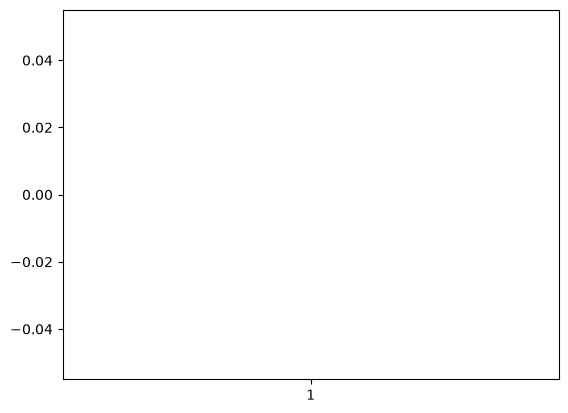

In [20]:
plt.boxplot(x=loan_history['loan_int_rate'])

In [21]:
loan_history.drop(loan_history.index[[32302,17839]],inplace=True)

In [22]:
loan_history[loan_history.customer_age > 80]

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
81,82.0,144,250000.0,RENT,4.0,VENTURE,B,4800.0,13.57,4,NaN,3,NO DEFAULT
183,184.0,144,200000.0,MORTGAGE,4.0,EDUCATION,A,6000.0,11.86,4,NaN,2,NO DEFAULT
577,576.0,123,80004.0,RENT,2.0,EDUCATION,A,20400.0,10.25,9,NaN,3,NO DEFAULT
749,748.0,123,78000.0,RENT,7.0,VENTURE,A,20000.0,NaN,9,NaN,4,NO DEFAULT
32302,32298.0,144,6000000.0,MORTGAGE,12.0,PERSONAL,C,5000.0,12.73,4,N,25,NO DEFAULT
32421,32417.0,94,24000.0,RENT,1.0,MEDICAL,C,6500.0,NaN,4,N,27,NO DEFAULT
32511,32507.0,84,94800.0,MORTGAGE,2.0,PERSONAL,A,10000.0,7.51,4,N,24,NO DEFAULT
32585,32581.0,99,42000.0,RENT,2.0,MEDICAL,B,6475.0,9.99,6,NaN,30,NO DEFAULT


In [23]:
# imputing the values in the position using median imputation

loan_history.loc[[81,183,577,749,32302,32421,32511,32585],'customer_age'] = loan_history['employment_duration'].median()

In [24]:
# identifying rows with the wrong stored data
loan_history[loan_history.employment_duration >50]

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
0,1.0,22,59000.0,RENT,123.0,PERSONAL,C,35000.0,16.02,10,Y,3,DEFAULT
210,211.0,21,192000.0,MORTGAGE,123.0,VENTURE,A,20000.0,6.54,10,NaN,4,NO DEFAULT


In [25]:
# imputing the values in the position using median imputation
loan_history.loc[[0,210],'employment_duration'] = loan_history['employment_duration'].median()

Text(0.5, 1.0, 'Employment duration')

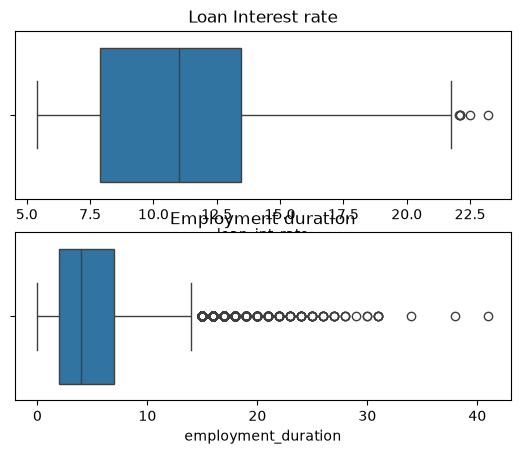

In [26]:
# Boxplot after imputating the wrong data value with median of the feature


fig, axs = plt.subplots(2,1)

# Create the box plot
sns.boxplot(x=loan_history['loan_int_rate'], ax= axs[0])
axs[0].set_title("Loan Interest rate")
sns.boxplot(x=loan_history['employment_duration'], ax= axs[1])
axs[1].set_title("Employment duration")

In [27]:
loan_history.sample(10)

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
3178,3177.0,24,40000.0,RENT,0.0,VENTURE,B,3500.0,NaN,4,NaN,2,NO DEFAULT
11781,11780.0,22,75744.0,MORTGAGE,6.0,VENTURE,A,6700.0,11.83,2,NaN,2,NO DEFAULT
8063,8062.0,24,49920.0,RENT,0.0,MEDICAL,B,7200.0,13.06,4,Y,3,NO DEFAULT
12151,12150.0,22,66000.0,RENT,6.0,DEBTCONSOLIDATION,D,11750.0,17.14,2,N,2,DEFAULT
5692,5691.0,23,45996.0,OWN,7.0,EDUCATION,B,10000.0,13.16,3,NaN,3,NO DEFAULT
879,878.0,22,10000.0,RENT,0.0,HOMEIMPROVEMENT,C,1000.0,14.74,2,N,4,DEFAULT
4213,4212.0,26,40000.0,MORTGAGE,5.0,MEDICAL,A,16000.0,NaN,7,NaN,3,NO DEFAULT
13468,13467.0,23,15600.0,RENT,3.0,EDUCATION,A,2500.0,10.65,3,N,2,DEFAULT
28103,28100.0,32,85000.0,MORTGAGE,1.0,EDUCATION,C,7500.0,10.78,2,Y,10,NO DEFAULT
29713,29710.0,37,36000.0,MORTGAGE,7.0,EDUCATION,A,9000.0,7.49,7,NaN,17,NO DEFAULT


In [28]:
# loan_history['customer_income']

In [29]:
loan_history.sample(5)

,customer_id,customer_age,customer_income,home_ownership,employment_duration,loan_intent,loan_grade,loan_amnt,loan_int_rate,term_years,historical_default,cred_hist_length,Current_loan_status
17818,17815.0,24,43680.0,RENT,1.0,EDUCATION,A,10800.0,5.42,4,NaN,4,NO DEFAULT
17949,17946.0,29,228000.0,MORTGAGE,11.0,DEBTCONSOLIDATION,D,35000.0,14.91,9,N,8,DEFAULT
12330,12329.0,22,80000.0,MORTGAGE,3.0,DEBTCONSOLIDATION,A,6000.0,7.40,2,NaN,3,NO DEFAULT
827,826.0,22,74800.0,RENT,3.0,MEDICAL,C,20000.0,14.96,9,Y,4,DEFAULT
13439,13438.0,22,35000.0,OWN,2.0,VENTURE,B,13200.0,13.48,2,NaN,3,NO DEFAULT


In [30]:
# Importing dependencied for Robust Scaler and object creation

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

In [31]:
# new processed dataset creation

loan_dataset = pd.DataFrame(index=loan_history.index)
loan_dataset["customer_id"] = loan_history['customer_id']

In [32]:
old_columns = ['customer_age','customer_income','employment_duration',
           'loan_amnt','loan_int_rate','term_years','cred_hist_length']

new_columns = ['customer_age_scaled','customer_income_scaled','employment_duration_scaled',
           'loan_amnt_scaled','loan_int_rate_scaled','term_years_scaled','cred_hist_length_scaled']


scaled_data = pd.DataFrame(
    scaler.fit_transform(loan_history[old_columns]),
    columns= new_columns,
    index= loan_history.index
)

loan_dataset[new_columns] = scaled_data

In [33]:
loan_dataset

,customer_id,customer_age_scaled,customer_income_scaled,employment_duration_scaled,loan_amnt_scaled,loan_int_rate_scaled,term_years_scaled,cred_hist_length_scaled
0,1.0,-0.571429,0.098280,0.0,3.750000,0.903052,1.50,-0.2
1,2.0,-0.714286,-1.115479,0.2,-0.972222,0.026930,-0.75,-0.4
2,3.0,-0.142857,-1.115479,-0.6,-0.347222,0.337522,0.25,-0.2
3,4.0,-0.428571,0.257985,0.0,3.750000,0.761221,1.50,-0.4
4,5.0,-0.285714,-0.014742,0.8,3.750000,0.588869,1.50,0.0
...,...,...,...,...,...,...,...,...
32581,32577.0,4.428571,-0.049140,-0.6,-0.305556,0.389587,0.75,5.2
32582,32578.0,4.000000,1.597052,0.0,1.336806,-0.628366,0.00,3.0
32583,32579.0,5.571429,0.515971,-0.2,3.750000,0.000000,0.25,4.8
32584,32580.0,4.285714,2.334152,0.2,0.972222,0.087971,0.50,4.4


In [34]:
# Applying Ordinal encoding in 'loan_grade'

grade = {
    "A":0,"B":1,"C":2,"D":3,"E":4
}

loan_dataset['loan_grade_encoded'] = loan_history['loan_grade'].map(grade)

In [35]:
# Applying Label encoding in 'historical_default'

def encode_label(x):
    if(x == 'Y'):
        return 1
    elif(x == 'N'):
        return 0
    else:
        return x

loan_dataset['historical_default_encoded'] = loan_history['historical_default'].map(encode_label)

In [36]:
loan_dataset['historical_default_encoded'].isna().sum()

np.int64(20734)

In [37]:
# Applying one-hot encoding on 'home_ownership' & 'loan_intent'
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

encoded_home_ownership = pd.get_dummies(loan_history[['home_ownership','loan_intent']], prefix=['ownership','intent'], dtype=int)
encoded_home_ownership

loan_dataset = pd.concat([loan_dataset,encoded_home_ownership],axis=1)

In [38]:
loan_dataset.sample(50)

,customer_id,customer_age_scaled,customer_income_scaled,employment_duration_scaled,loan_amnt_scaled,loan_int_rate_scaled,term_years_scaled,cred_hist_length_scaled,loan_grade_encoded,historical_default_encoded,ownership_MORTGAGE,ownership_OTHER,ownership_OWN,ownership_RENT,intent_DEBTCONSOLIDATION,intent_EDUCATION,intent_HOMEIMPROVEMENT,intent_MEDICAL,intent_PERSONAL,intent_VENTURE
3270,3269.0,-0.571429,-0.466830,0.4,-0.069444,-0.244165,-0.50,-0.4,0,NaN,0,0,1,0,0,1,0,0,0,0
29047,29044.0,0.142857,0.712531,-0.2,-0.138889,-0.664273,0.75,1.2,0,NaN,1,0,0,0,1,0,0,0,0,0
29640,29637.0,1.857143,-0.515971,-0.6,-0.388889,-0.220826,1.25,2.4,1,NaN,1,0,0,0,0,0,0,0,0,1
7347,7346.0,-0.428571,-0.208845,-0.6,-0.416667,-0.628366,-0.25,-0.2,0,0.0,1,0,0,0,0,0,0,1,0,0
32052,32048.0,1.428571,4.791155,-0.4,1.666667,-0.558348,0.50,2.6,0,0.0,0,0,0,1,1,0,0,0,0,0
23195,23192.0,0.285714,0.122850,0.2,1.111111,0.213645,1.00,1.0,1,NaN,0,1,0,0,0,0,0,0,1,0
3839,3838.0,-0.142857,-0.405504,0.6,0.000000,-0.890485,0.25,0.0,0,NaN,1,0,0,0,0,1,0,0,0,0
31894,31890.0,2.285714,4.152334,2.4,2.361111,0.156194,-0.50,2.2,1,NaN,1,0,0,0,0,1,0,0,0,0
32312,32308.0,4.000000,-0.031941,-0.6,3.034722,NaN,0.00,4.8,3,1.0,0,0,0,1,0,0,1,0,0,0
23368,23365.0,0.714286,0.565111,-0.4,0.000000,-0.554758,-0.75,0.6,0,NaN,0,0,0,1,0,0,0,0,0,1
